In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# @title
def increase_font():
  from IPython.display import Javascript
  display(Javascript('''
  for (rule of document.styleSheets[0].cssRules){
    if (rule.selectorText=='body') {
      rule.style.fontSize = '30px'
      rule.style.color = 'darkblue'
      break
    }
  }
  '''))
increase_font()
get_ipython().events.register('pre_run_cell', increase_font)
print("Is this visible")
print("...to all here ")

<IPython.core.display.Javascript object>

Is this visible
...to all here 


In [3]:
np.set_printoptions(precision=0)
pd.options.display.float_format = '{:,.2f}'.format  # Complete option to format floats / ints
pd.set_option('display.precision', 2) # shorter for floats / decimals only
plt.rcParams['figure.figsize'] = [14, 8]

<IPython.core.display.Javascript object>

In [4]:
movie_df = pd.read_csv("/content/Movie_Database.csv", encoding= 'latin1')
movie_df

<IPython.core.display.Javascript object>

,Movie,Year,Genres,Certification/Rating,IMDb ID,Writer,Director
0,300,2006,"Action, Drama",R,tt0416449,Zack Snyder,Zack Snyder
1,1408,2007,"Fantasy, Horror, Mystery",PG-13,tt0450385,Matt Greenberg,Mikael Håfström
2,2012,2009,"Action, Adventure, Sci-Fi",PG-13,tt1190080,Roland Emmerich,Roland Emmerich
3,12 Angry Men,1957,"Crime, Drama",Approved,tt0050083,Reginald Rose,Sidney Lumet
4,12 Strong,2018,"Action, Drama, History",R,tt1413492,Ted Tally,Nicolai Fuglsig
...,...,...,...,...,...,...,...
611,Wrath Of Man,2021,"Action, Crime, Thriller",R,tt11083552,Nicolas Boukhrief,Guy Ritchie
612,X-Men First Class,2011,"Action, Sci-Fi",PG-13,tt1270798,Ashley Miller,Matthew Vaughn
613,You Only Live Twice,1967,"Action, Adventure, Thriller",PG,tt0062512,Harold Jack Bloom,Lewis Gilbert
614,Zack Snyder's Justice League,2021,"Action, Adventure, Fantasy",R,tt12361974,Jerry Siegel,Zack Snyder


In [5]:
print("🔹 Dataset Shape:", movie_df.shape)
print("🔹 Columns:\n", movie_df.columns)
movie_df.info()

<IPython.core.display.Javascript object>

🔹 Dataset Shape: (616, 7)
🔹 Columns:
 Index(['Movie', 'Year', 'Genres', 'Certification/Rating', 'IMDb ID', 'Writer',
       'Director'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 616 entries, 0 to 615
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Movie                 616 non-null    object
 1   Year                  616 non-null    int64 
 2   Genres                616 non-null    object
 3   Certification/Rating  592 non-null    object
 4   IMDb ID               616 non-null    object
 5   Writer                614 non-null    object
 6   Director              614 non-null    object
dtypes: int64(1), object(6)
memory usage: 33.8+ KB


In [6]:
print("🔍 Missing Values:\n")
print(movie_df.isnull().sum())

<IPython.core.display.Javascript object>

🔍 Missing Values:

Movie                    0
Year                     0
Genres                   0
Certification/Rating    24
IMDb ID                  0
Writer                   2
Director                 2
dtype: int64


In [7]:
for col in movie_df.select_dtypes(include=['object']).columns:
    movie_df[col].fillna(movie_df['Certification/Rating'].mode()[0], inplace=True)

<IPython.core.display.Javascript object>

In [8]:
print(movie_df.isnull().sum())

<IPython.core.display.Javascript object>

Movie                   0
Year                    0
Genres                  0
Certification/Rating    0
IMDb ID                 0
Writer                  0
Director                0
dtype: int64


In [9]:
print(movie_df.describe())

<IPython.core.display.Javascript object>

          Year
count   616.00
mean  2,007.63
std      12.10
min   1,956.00
25%   2,002.75
50%   2,011.00
75%   2,015.00
max   2,023.00


In [10]:
# Unique Values per feature
print("🎯Unique Values:")
for col in movie_df.columns:
    print(f"{col}: {movie_df[col].nunique()}")


<IPython.core.display.Javascript object>

🎯Unique Values:
Movie: 616
Year: 62
Genres: 143
Certification/Rating: 11
IMDb ID: 614
Writer: 471
Director: 403


In [11]:
from collections import Counter

genre_list = sum([g.split(', ') for g in movie_df['Genres'].dropna()], [])
genre_counts = Counter(genre_list)
print("Top 10 Genres:", genre_counts.most_common(10))


<IPython.core.display.Javascript object>

Top 10 Genres: [('Action', 337), ('Drama', 286), ('Adventure', 220), ('Thriller', 158), ('Sci-Fi', 100), ('Crime', 95), ('Comedy', 83), ('Romance', 78), ('Mystery', 67), ('Fantasy', 42)]


In [12]:
print("📛 Rating Distribution:")
print(movie_df['Certification/Rating'].value_counts())


<IPython.core.display.Javascript object>

📛 Rating Distribution:
Certification/Rating
PG-13        270
R            238
PG            64
Not Rated     17
TV-MA          9
G              8
Unrated        6
Approved       1
GP             1
TV-14          1
NC-17          1
Name: count, dtype: int64


In [13]:
print("🎬 Top 5 Directors:")
print(movie_df['Director'].value_counts().head())

print("\n✍️ Top 5 Writers:")
print(movie_df['Writer'].value_counts().head())


<IPython.core.display.Javascript object>

🎬 Top 5 Directors:
Director
Steven Spielberg    12
Ridley Scott         8
Edward Zwick         6
Justin Lin           6
Roland Emmerich      6
Name: count, dtype: int64

✍️ Top 5 Writers:
Writer
Richard Maibaum    9
James Cameron      7
Steven Knight      5
Lilly Wachowski    5
Chris Morgan       5
Name: count, dtype: int64


In [14]:
print("📅 Year Range:", movie_df['Year'].min(), "to", movie_df['Year'].max())
print(movie_df['Year'].value_counts().sort_index().tail(10))  # Recent 10 years

<IPython.core.display.Javascript object>

📅 Year Range: 1956 to 2023
Year
2014    35
2015    47
2016    33
2017    15
2018    20
2019    18
2020    12
2021    19
2022    20
2023    11
Name: count, dtype: int64


In [15]:
duplicates = movie_df.duplicated().sum()
print("🌀 Duplicates Found:", duplicates)

<IPython.core.display.Javascript object>

🌀 Duplicates Found: 0


<IPython.core.display.Javascript object>

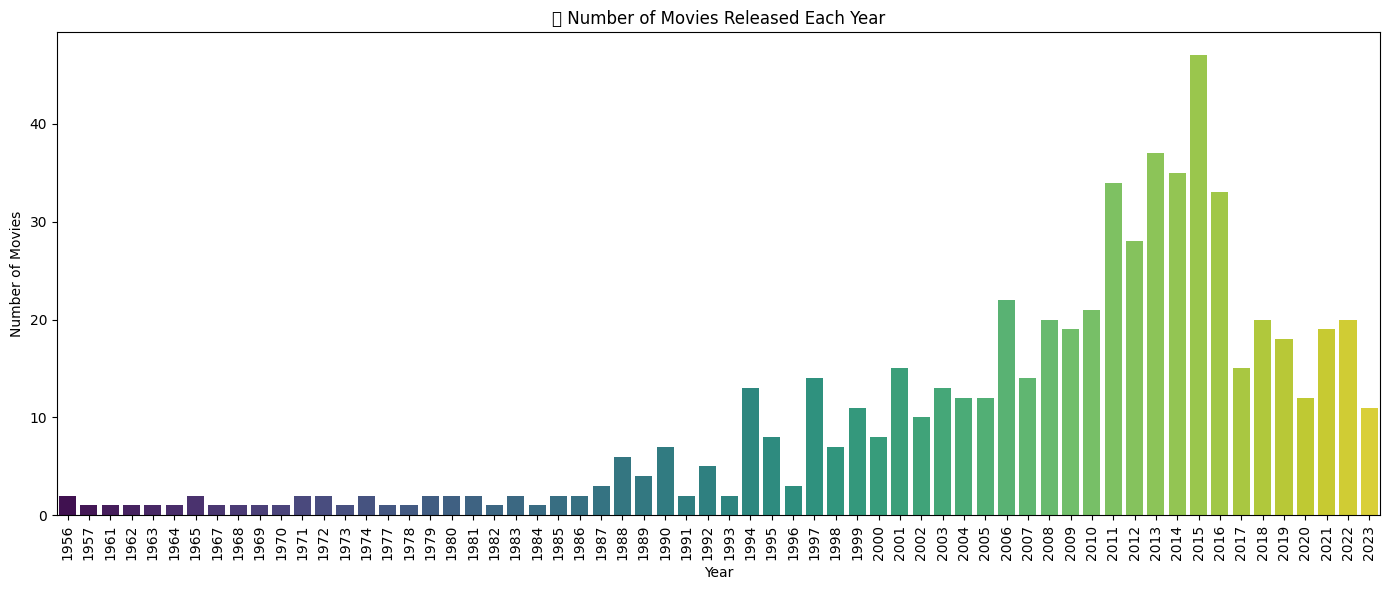

In [16]:

plt.figure(figsize=(14, 6))
sns.countplot(data=movie_df, x='Year', order=movie_df['Year'].value_counts().sort_index().index, palette='viridis')
plt.xticks(rotation=90)
plt.title("🎬 Number of Movies Released Each Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

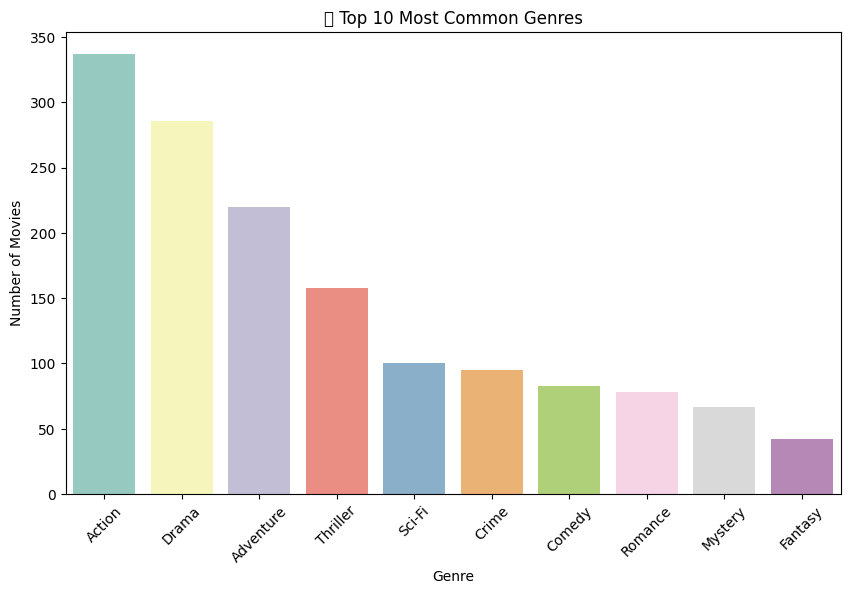

In [17]:
from collections import Counter

# Split all genres and count
genre_list = sum([g.split(', ') for g in movie_df['Genres'].dropna()], [])
genre_counts = Counter(genre_list)
top_genres = genre_counts.most_common(10)

genres, counts = zip(*top_genres)

plt.figure(figsize=(10, 6))
sns.barplot(x=list(genres), y=list(counts), palette="Set3")
plt.title("🎭 Top 10 Most Common Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

<IPython.core.display.Javascript object>

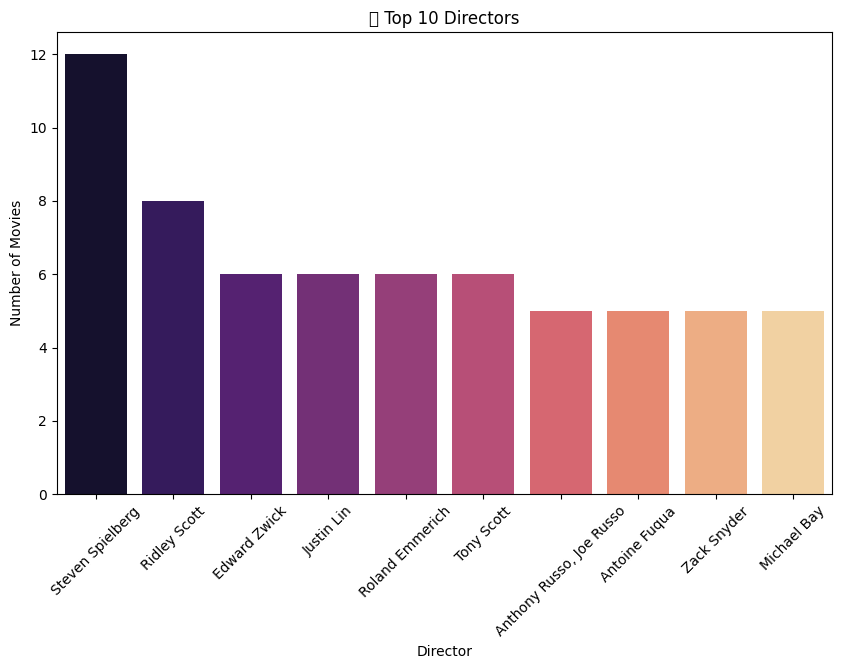

In [18]:
top_directors = movie_df['Director'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_directors.index, y=top_directors.values, palette="magma")
plt.title("🎥 Top 10 Directors")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

<IPython.core.display.Javascript object>

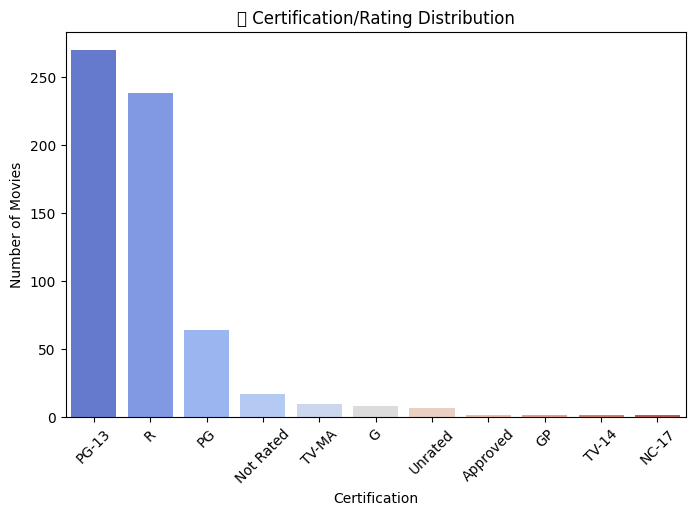

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=movie_df, x='Certification/Rating', order=movie_df['Certification/Rating'].value_counts().index, palette="coolwarm")
plt.title("🔞 Certification/Rating Distribution")
plt.xlabel("Certification")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

<IPython.core.display.Javascript object>

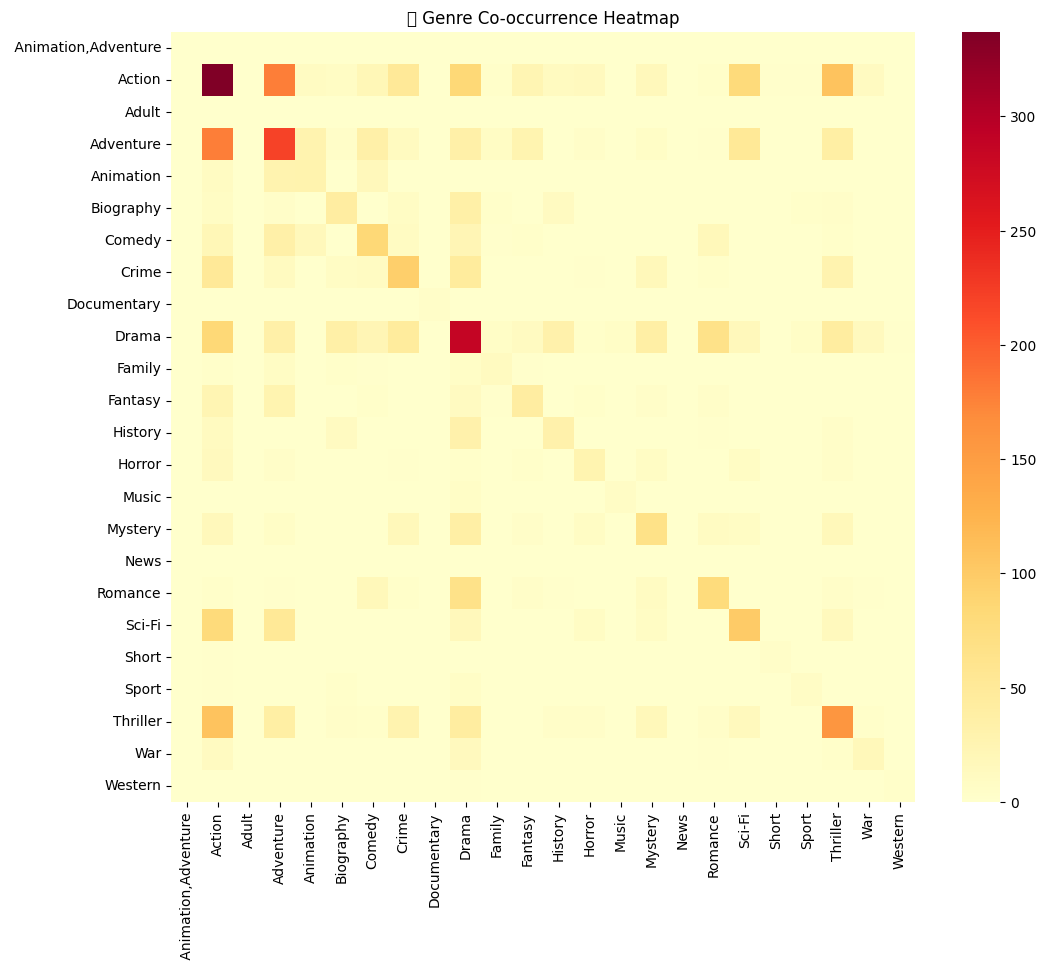

In [20]:
from sklearn.preprocessing import MultiLabelBinarizer
import pandas as pd

# Transform genres into binary format
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(movie_df['Genres'].str.split(', '))
genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_)

# Compute co-occurrence matrix
genre_cooccurrence = genre_df.T.dot(genre_df)

plt.figure(figsize=(12, 10))
sns.heatmap(genre_cooccurrence, cmap='YlOrRd', annot=False)
plt.title("📌 Genre Co-occurrence Heatmap")
plt.show()

<IPython.core.display.Javascript object>

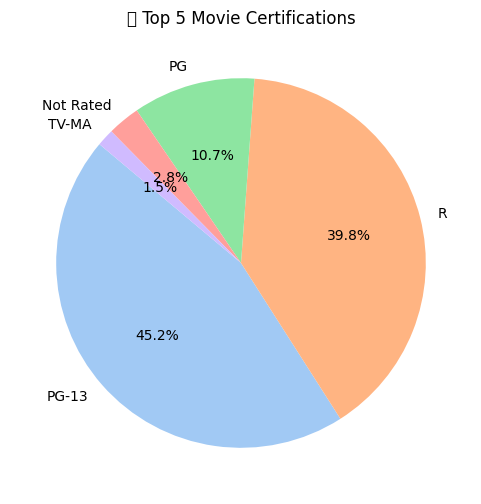

In [21]:
top_certs = movie_df['Certification/Rating'].value_counts().head(5)

plt.figure(figsize=(6, 6))
plt.pie(top_certs, labels=top_certs.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title("🔖 Top 5 Movie Certifications")
plt.show()

In [22]:
pip install streamlit

<IPython.core.display.Javascript object>

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 4.9 MB/s eta 0:00:00


<IPython.core.display.Javascript object>

2025-04-22 16:51:41.859 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-04-22 16:51:41.920 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-04-22 16:51:43.383 
  command:

    streamlit run /usr/local/lib/python3.11/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-04-22 16:51:43.393 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-04-22 16:51:43.405 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-04-22 16:51:43.407 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-04-22 16:51:43.413 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

DeltaGenerator()

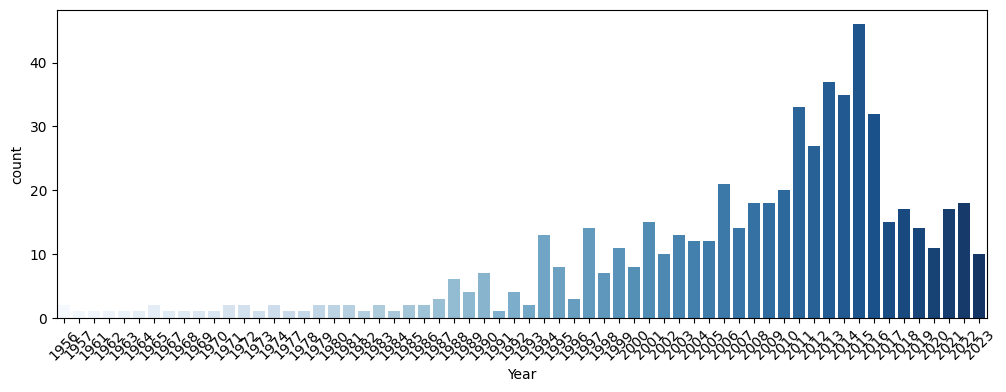

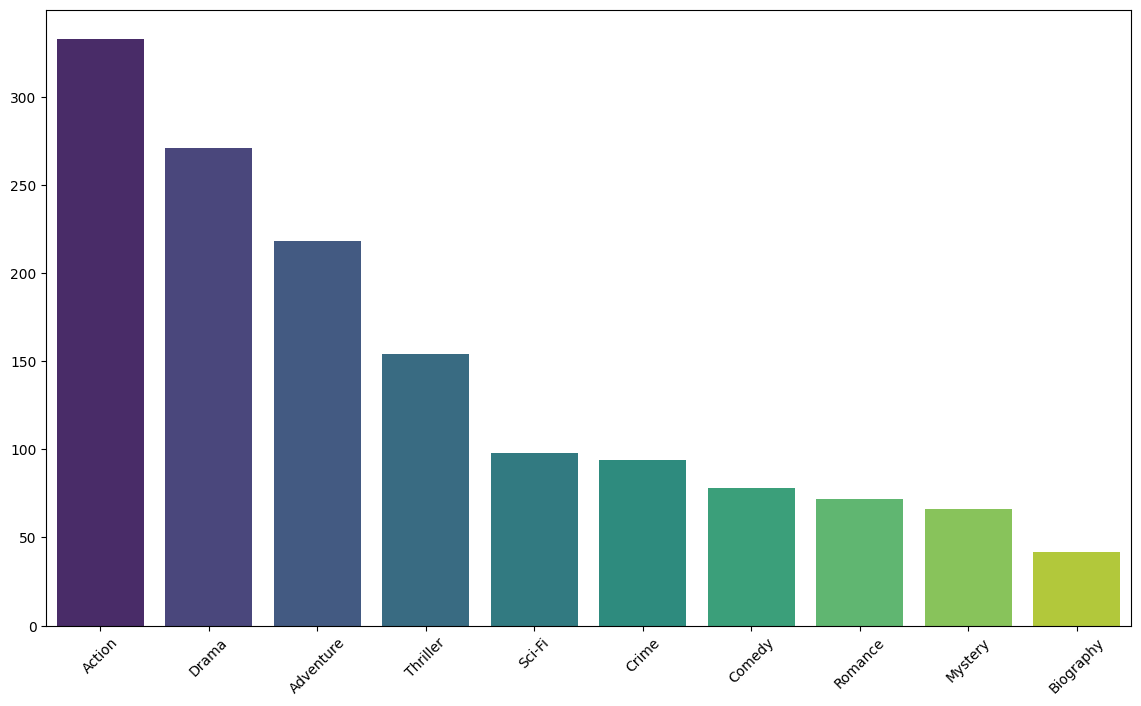

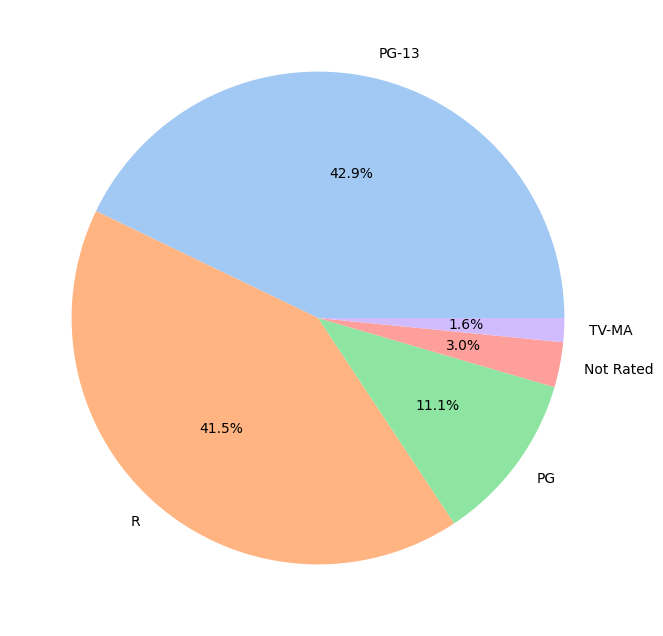

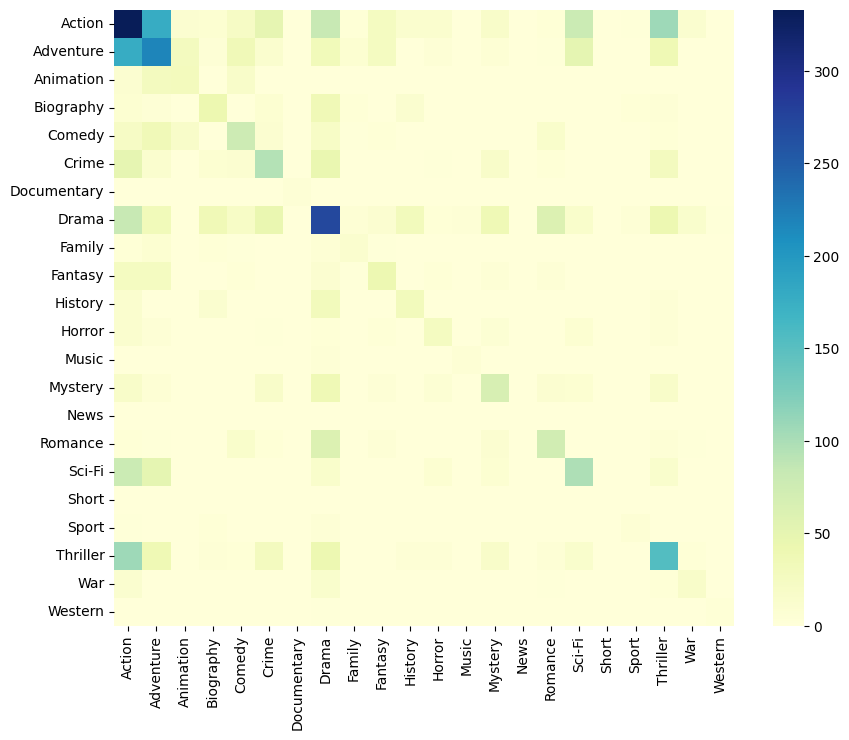

In [23]:
import streamlit as st
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer

st.set_page_config(page_title="🎬 Movie Data Dashboard", layout="wide")

# Load your dataset
movie_df = pd.read_csv("Movie_Database.csv", encoding='ISO-8859-1')

st.title("🎬 Movie Dataset Dashboard")

# Sidebar Filters
st.sidebar.header("🔎 Filter Options")
years = sorted(movie_df['Year'].dropna().unique())
selected_years = st.sidebar.multiselect("Select Year(s)", years, default=years)

genres_raw = sum([g.split(', ') for g in movie_df['Genres'].dropna()], [])
genres_unique = sorted(set(genres_raw))
selected_genres = st.sidebar.multiselect("Select Genre(s)", genres_unique, default=genres_unique)

ratings = movie_df['Certification/Rating'].dropna().unique()
selected_ratings = st.sidebar.multiselect("Select Certification(s)", ratings, default=ratings)

# Apply Filters
filtered_df = movie_df[
    (movie_df['Year'].isin(selected_years)) &
    (movie_df['Certification/Rating'].isin(selected_ratings)) &
    (movie_df['Genres'].apply(lambda g: any(genre in g for genre in selected_genres)))
]

st.markdown(f"### Showing {len(filtered_df)} Movies based on filters")

# --- Plot 1: Movies Per Year
st.subheader("📊 Number of Movies Released per Year")
fig1, ax1 = plt.subplots(figsize=(12, 4))
sns.countplot(data=filtered_df, x='Year', order=sorted(filtered_df['Year'].unique()), ax=ax1, palette='Blues')
plt.xticks(rotation=45)
st.pyplot(fig1)

# --- Plot 2: Top Genres
st.subheader("🎭 Top Genres")
genre_list = sum([g.split(', ') for g in filtered_df['Genres'].dropna()], [])
genre_counts = Counter(genre_list)
top_genres = genre_counts.most_common(10)
genres, counts = zip(*top_genres)

fig2, ax2 = plt.subplots()
sns.barplot(x=list(genres), y=list(counts), ax=ax2, palette="viridis")
plt.xticks(rotation=45)
st.pyplot(fig2)

# --- Plot 3: Certifications
st.subheader("🔖 Certification Distribution")
certs = filtered_df['Certification/Rating'].value_counts()
fig3, ax3 = plt.subplots()
ax3.pie(certs.head(5), labels=certs.head(5).index, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
st.pyplot(fig3)

# --- Plot 4: Genre Co-occurrence Heatmap
st.subheader("📌 Genre Co-occurrence Heatmap")
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(filtered_df['Genres'].str.split(', '))
genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_)
co_matrix = genre_df.T.dot(genre_df)

fig4, ax4 = plt.subplots(figsize=(10, 8))
sns.heatmap(co_matrix, cmap="YlGnBu", ax=ax4)
st.pyplot(fig4)

In [26]:
pip install scikit-learn

<IPython.core.display.Javascript object>

In [27]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Load dataset
movie_df = pd.read_csv("Movie_Database.csv", encoding='ISO-8859-1')

# Fill NaNs
movie_df.fillna('', inplace=True)

# Create a "metadata soup" for content filtering
movie_df['soup'] = movie_df['Genres'] + ' ' + movie_df['Director'] + ' ' + movie_df['Writer']

# --- Content-Based Filtering using TF-IDF ---
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(movie_df['soup'])

# Compute cosine similarity matrix
content_similarity = cosine_similarity(tfidf_matrix, tfidf_matrix)

# --- Simulated Collaborative Filtering ---
# Let's simulate using Year and Certification/Rating as a proxy
movie_df['collab_features'] = movie_df['Year'].astype(str) + ' ' + movie_df['Certification/Rating']
collab_vectorizer = TfidfVectorizer()
collab_matrix = collab_vectorizer.fit_transform(movie_df['collab_features'])
collab_similarity = cosine_similarity(collab_matrix, collab_matrix)

# --- Hybrid Filtering: Weighted Sum of Content + Collab ---
hybrid_similarity = (0.7 * content_similarity) + (0.3 * collab_similarity)

# --- Recommendation Function ---
def recommend_movies(title, top_n=5):
    if title not in movie_df['Movie'].values:
        return f"Movie '{title}' not found in the database."

    idx = movie_df[movie_df['Movie'] == title].index[0]
    sim_scores = list(enumerate(hybrid_similarity[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:top_n+1]  # Exclude the movie itself

    recommended_movies = [movie_df.iloc[i[0]]['Movie'] for i in sim_scores]
    return recommended_movies

# --- Example Usage ---
print("Recommended Movies for '300':")
print(recommend_movies("300"))

<IPython.core.display.Javascript object>

Recommended Movies for '300':
['Man of Steel', 'Watchmen', "Zack Snyder's Justice League", '300 Rise Of An Empire', 'Batman V Superman Dawn Of Justice']


In [28]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Simulated User Ratings Matrix
# Rows: Users, Columns: Movies, Values: Ratings
ratings_dict = {
    '300':         [5, 4, 0, 2],
    '12 Angry Men': [3, 0, 5, 4],
    '2012':         [0, 5, 4, 0],
    '1408':         [2, 3, 0, 5],
    '12 Strong':    [5, 0, 4, 3],
}

ratings_df = pd.DataFrame(ratings_dict, index=['User1', 'User2', 'User3', 'User4'])

# Transpose to make it Movie-Based
movie_user_matrix = ratings_df.T

# Compute cosine similarity between movies
collab_similarity = cosine_similarity(movie_user_matrix)
collab_similarity_df = pd.DataFrame(collab_similarity, index=movie_user_matrix.index, columns=movie_user_matrix.index)

<IPython.core.display.Javascript object>

In [29]:
def recommend_collab(movie_title, top_n=3):
    if movie_title not in collab_similarity_df.columns:
        return f"Movie '{movie_title}' not found."

    sim_scores = collab_similarity_df[movie_title].sort_values(ascending=False)
    top_movies = sim_scores.iloc[1:top_n+1].index.tolist()  # Exclude the movie itself
    return top_movies

# Example
print("Collaborative Recommendations for '300':")
print(recommend_collab("300"))

<IPython.core.display.Javascript object>

Collaborative Recommendations for '300':
['1408', '12 Strong', '12 Angry Men']


In [30]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# --- Load movie metadata ---
movie_df = pd.read_csv("Movie_Database.csv", encoding='ISO-8859-1')
movie_df.fillna('', inplace=True)

# --- Content-Based Filtering ---
movie_df['soup'] = movie_df['Genres'] + ' ' + movie_df['Director'] + ' ' + movie_df['Writer']
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(movie_df['soup'])
content_similarity = cosine_similarity(tfidf_matrix, tfidf_matrix)

# --- Collaborative Filtering (Simulated User Ratings) ---
ratings_dict = {
    '300': [5, 4, 0, 2],
    '12 Angry Men': [3, 0, 5, 4],
    '2012': [0, 5, 4, 0],
    '1408': [2, 3, 0, 5],
    '12 Strong': [5, 0, 4, 3],
}
ratings_df = pd.DataFrame(ratings_dict, index=['User1', 'User2', 'User3', 'User4'])
movie_user_matrix = ratings_df.T
collab_similarity = cosine_similarity(movie_user_matrix)
collab_df = pd.DataFrame(collab_similarity, index=movie_user_matrix.index, columns=movie_user_matrix.index)

# --- Align movie titles from ratings to the main dataset ---
# Add default zero similarity for non-rated movies
def get_collab_similarity(title):
    if title in collab_df.index:
        idx = movie_df[movie_df['Movie'] == title].index[0]
        collab_sim_scores = []
        for movie in movie_df['Movie']:
            if movie in collab_df.columns:
                score = collab_df.loc[title, movie]
            else:
                score = 0
            collab_sim_scores.append(score)
        return collab_sim_scores
    else:
        return [0] * len(movie_df)

# --- Final Hybrid Recommendation Function ---
def hybrid_recommend(movie_title, top_n=5, alpha=0.7):
    if movie_title not in movie_df['Movie'].values:
        return f"Movie '{movie_title}' not found."

    idx = movie_df[movie_df['Movie'] == movie_title].index[0]

    # Content similarity row
    content_scores = content_similarity[idx]

    # Collaborative similarity row
    collab_scores = get_collab_similarity(movie_title)

    # Combine both
    hybrid_scores = alpha * content_scores + (1 - alpha) * pd.Series(collab_scores)

    # Sort and return top matches
    top_indices = hybrid_scores.argsort()[::-1][1:top_n+1]
    recommended = movie_df.iloc[top_indices]['Movie'].tolist()
    return recommended

# --- Example Usage ---
print("🎬 Hybrid Recommendations for '300':")
print(hybrid_recommend("300"))

<IPython.core.display.Javascript object>

🎬 Hybrid Recommendations for '300':
['Man of Steel', 'Watchmen', "Zack Snyder's Justice League", '300 Rise Of An Empire', 'Batman V Superman Dawn Of Justice']
